Equazione della parabola: y = 0.074x^2 + -2.070x + 14.932

Valori previsti dal modello:
x = 0.0 -> y = 14.93
x = 1.0 -> y = 12.94
x = 2.0 -> y = 11.09
x = 3.0 -> y = 9.39
x = 4.0 -> y = 7.83
x = 5.0 -> y = 6.43
x = 6.0 -> y = 5.17
x = 7.0 -> y = 4.07
x = 8.0 -> y = 3.10
x = 9.0 -> y = 2.29
x = 10.0 -> y = 1.63
x = 11.0 -> y = 1.11
x = 12.0 -> y = 0.74
x = 13.0 -> y = 0.52
x = 14.0 -> y = 0.45
x = 15.0 -> y = 0.52
x = 16.0 -> y = 0.74
x = 17.0 -> y = 1.11
x = 18.0 -> y = 1.63
x = 19.0 -> y = 2.30
x = 20.0 -> y = 3.11



Valore simulato valido: x = 1.00, y = 13.21
Valore simulato valido: x = 2.00, y = 11.01
Valore simulato valido: x = 3.00, y = 9.20
Valore simulato valido: x = 4.00, y = 7.67
Valore simulato valido: x = 5.00, y = 6.33
Valore simulato valido: x = 5.61, y = 5.61
Valore simulato valido: x = 6.00, y = 5.19
Valore simulato valido: x = 7.00, y = 4.13
Valore simulato valido: x = 8.00, y = 3.24
Valore simulato valido: x = 9.00, y = 2.44
Valore simulato valido: x = 10.00, y = 1.73

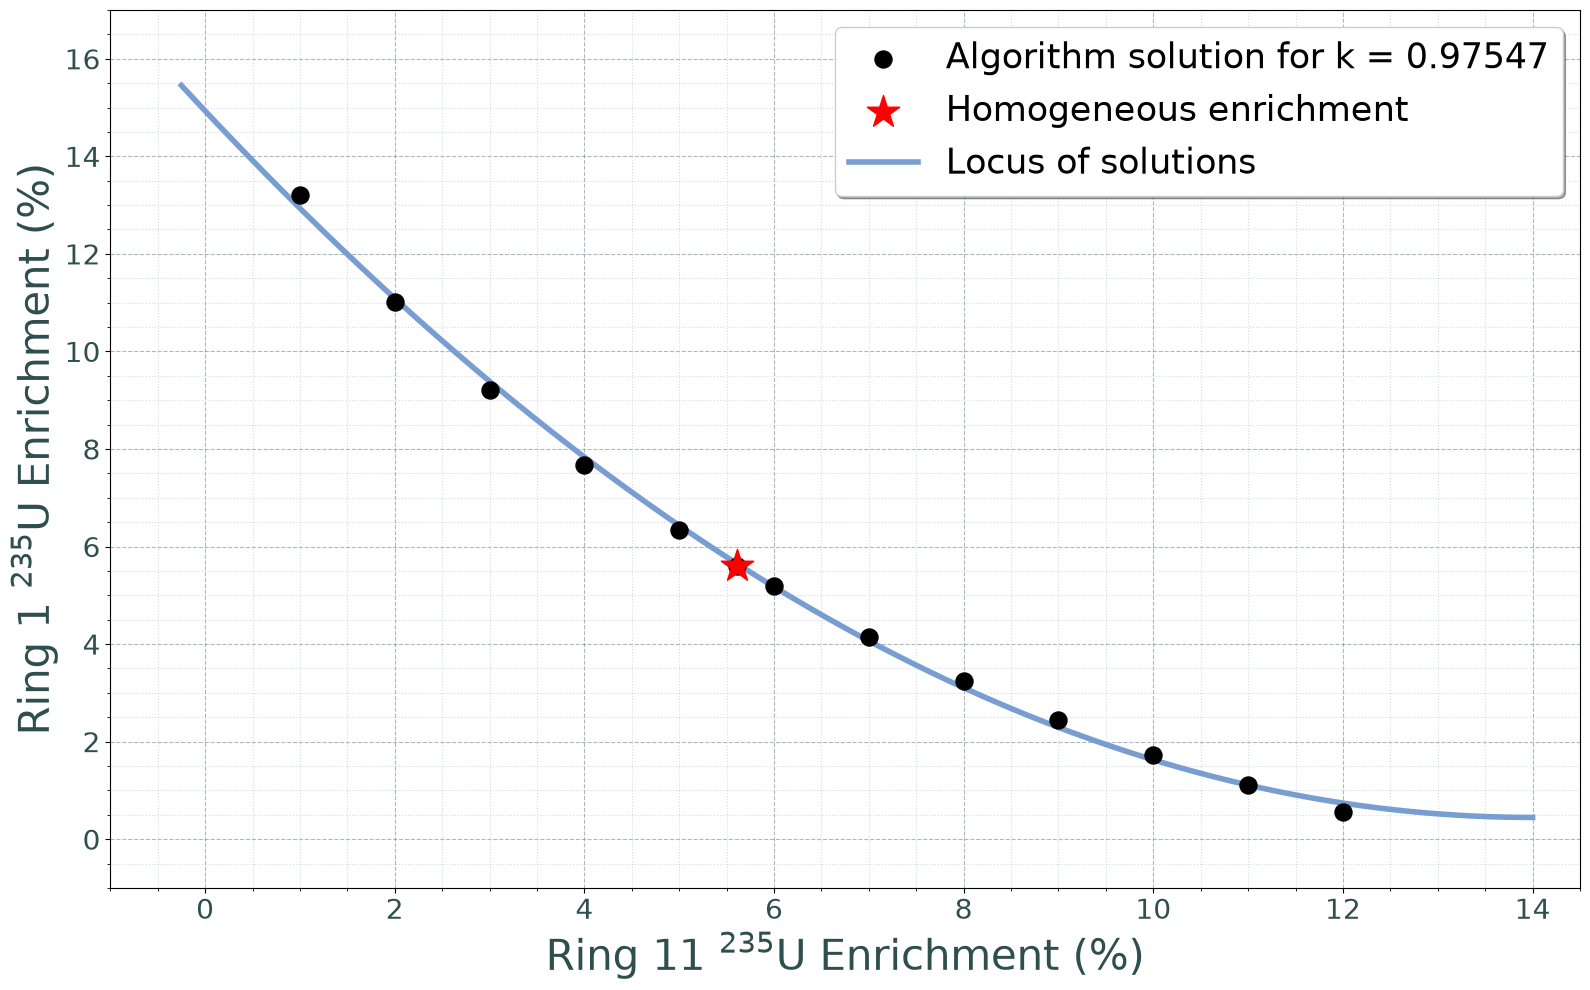

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def analizza_e_plotta(file_path):
    """
    Legge i dati di simulazione, esegue regressione parabolica ESCLUDENDO i punti con y=0,
    e genera il plot sul VERO arricchimento del primo anello fisico.
    """
    # Definizione manuale delle colonne
    nomi_colonne = [
        'Pres', 'moltiplicatore', 'PERC_water', 'Arricch_MAX',
        'Arricch_min', 'T_WATER', 'T_FUEL', 'K_max', 'std_k_max',
        'K_auto', 'std_k_auto', 'Compatibilità'
    ]
    
    # Lettura del file
    df = pd.read_csv(file_path, sep=r'\s+', skiprows=3, names=nomi_colonne, engine='python')
    
    # Estrazione array completi
    x_tutti = df['Arricch_min'].values
    a_M_tutti = df['Arricch_MAX'].values  # Questo è il valore nominale (i=0)
    
    # --- MODIFICA 1: Calcolo VERO arricchimento del primo anello fisico (i=2) ---
    # Formula originale OpenMC: e_i = a_M - (a_M - a_m) * (i / (num_rings - 1))
    y_tutti = np.zeros_like(a_M_tutti)
    for idx in range(len(a_M_tutti)):
            y_tutti[idx] = a_M_tutti[idx] - (a_M_tutti[idx] - x_tutti[idx]) * (2.0 / 12.0)


    # Creiamo maschere booleane per separare i dati validi da quelli nulli
    maschera_validi = y_tutti > -50
    maschera_zeri = y_tutti == 0

    x_validi = x_tutti[maschera_validi]
    y_validi = y_tutti[maschera_validi]


    # --- MODIFICA 2: Regressione solo sui dati validi ---
    a, b, c = np.polyfit(x_validi, y_validi, 2)

    # Vettori per l'estrapolazione del modello (x da 1 a 20)
    x_pred = np.arange(0, 21)
    y_pred = a * x_pred**2 + b * x_pred + c

    # Output analitico a terminale
    print(f"Equazione della parabola: y = {a:.3f}x^2 + {b:.3f}x + {c:.3f}\n")
    print("Valori previsti dal modello:")
    for x, y in zip(x_pred, y_pred):
        print(f"x = {x:2.1f} -> y = {y:.2f}")

    print("\n\n")
    
    for x, y in zip(x_validi, y_validi):
        print(f"Valore simulato valido: x = {x:.2f}, y = {y:.2f}")

   # Configurazione della Figura
    fig, ax = plt.subplots(figsize=(16, 10))

    # --- MODIFICA 3: Plot differenziato dei dati di simulazione ---
    ax.scatter(x_validi, y_validi, color='#000000', s=150, zorder=5, label='Algorithm solution for k = 0.97547')

    # se l'srricchimento è omogeneo deve plottare con un marker diverso e metterlo in legenda
    if (x_validi == y_validi).any():
        ax.scatter(x_validi[x_validi == y_validi], y_validi[x_validi == y_validi], color='#FF0000', s=600, marker='*', zorder=6, label='Homogeneous enrichment')
         
    # Plot della curva di regressione
    x_full = np.linspace(-0.25, 14, 1000) 
    y_full = a * x_full**2 + b * x_full + c
    
    # Formattazione equazione nel label per gestire bene i segni
    segno_b = "+" if b >= 0 else ""
    segno_c = "+" if c >= 0 else ""
    label_eq = f'Locus of solutions'
    ax.plot(x_full, y_full, color='#789DD1', linestyle='-', linewidth=4, zorder=4, label=label_eq)

    # Formattazione Assi (Font 22, nessun grassetto)
    ax.set_xlabel('Ring 11 $^{235}$U Enrichment (%)', fontsize=30, color='#2F4F4F')
    ax.set_ylabel('Ring 1 $^{235}$U Enrichment (%)', fontsize=30, color='#2F4F4F')

    ax.set_xlim(-1, 14.5)
    ax.set_ylim(-1, 17)

    # Formattazione Tick
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=20, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=15)

    # Setup della griglia
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Setup Legenda (loc='best', fontsize=20)
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=25, facecolor="#FFFFFF")

    plt.tight_layout()
    plt.savefig('regressione_parabolica_filtrata.png', dpi=300)
    plt.show()

    return a, b, c

a, b, c = analizza_e_plotta('../result_final.txt')

Se scrivi un breve script per calcolare questa sommatoria per ogni coppia di $(a_{int}, a_{ext})$ che hai verificato nel test di circolarità, il risultato non sarà matematicamente identico fino all'ultimo decimale, ma seguirà una fisica ben precisa.L'Ordine di Grandezza: Il valore della sommatoria rimarrà per lo più costante, dimostrando che stai analizzando core con lo stesso inventario di fissile.La Variazione Fina (Importanza Neutronica): Noterai una leggera discrepanza sistematica. Quando metti l'arricchimento maggiore al centro, la sommatoria totale (massa totale) necessaria per ottenere il $k_{max}$ sarà leggermente inferiore rispetto a quando sposti l'arricchimento in periferia.Questo avviene perché il flusso termico $\phi$ è massimo al centro del nocciolo. Un atomo di $U^{235}$ posizionato al centro ha un'importanza spaziale maggiore rispetto a uno al bordo. Quindi, per eguagliare la reattività, ti serve meno massa totale se la concentri al centro, e più massa totale se la spargi verso l'esterno dove i neutroni sfuggono (leakage).


Ecco l'analisi scientifica del risultato:La Tendenza: La pendenza è chiaramente positiva. Man mano che aumenti l'arricchimento periferico (EXT) e svuoti il centro, la massa totale proporzionale di U-235 necessaria per mantenere l'autovalore bersaglio $k_{max}$ aumenta.La Fisica (Leakage e Importanza): Al centro del reattore, il flusso neutronico $\phi$ è massimo. Un atomo fissile lì posizionato ha una probabilità nettamente maggiore di intercettare un neutrone termico e generare fissione rispetto allo stesso atomo posizionato sull'anello esterno.La "Tassa di Fuga": Spostando il materiale verso l'esterno (dove l'arricchimento EXT cresce), le fissioni avvengono in prossimità del confine del moderatore, aumentando vertiginosamente la probabilità di leakage (fuga dei neutroni dal sistema). Per compensare questa inefficienza spaziale e ottenere lo stesso bilancio globale, il tuo algoritmo è stato costretto ad immettere più massa totale.La Scala del Fenomeno: Osserva attentamente l'asse Y. Il valore oscilla da $\sim 20.245$ a $\sim 20.295$. Stiamo parlando di una deviazione relativa dello 0.25%. È una fluttuazione microscopica: ecco perché nel grafico di circolarità precedente i valori di $k$ sembravano formare una linea piatta perfetta. Al primo ordine la massa è invariante, al secondo ordine paghi l'efficienza spaziale.Hai matematicamente quantificato la "penalità" neutronica legata all'appiattimento radiale del nocciolo.

### --- Analisi Rette --- ###

Retta 0 [Teorica: P(0, 15.648) -> P(12, 1.000)]: Media = 7.103
Retta 1 [Teorica: P(0, 12.817) -> P(12, 2.000)]: Media = 6.507
Retta 2 [Teorica: P(0, 10.441) -> P(12, 3.000)]: Media = 6.100
Retta 3 [Teorica: P(0, 8.410) -> P(12, 4.000)]: Media = 5.838
Retta 4 [Teorica: P(0, 6.600) -> P(12, 5.000)]: Media = 5.667
Retta 5 [Teorica: P(0, 5.609) -> P(12, 5.609)]: Media = 5.609
Retta 6 [Teorica: P(0, 5.025) -> P(12, 6.000)]: Media = 5.594
Retta 7 [Teorica: P(0, 3.562) -> P(12, 7.000)]: Media = 5.568
Retta 8 [Teorica: P(0, 2.288) -> P(12, 8.000)]: Media = 5.620
Retta 9 [Teorica: P(0, 1.130) -> P(12, 9.000)]: Media = 5.721
Retta 10 [Teorica: P(0, 0.079) -> P(12, 10.000)]: Media = 5.866
Retta 11 [Teorica: P(0, -0.873) -> P(12, 11.000)]: Media = 6.053
Retta 12 [Teorica: P(0, -1.737) -> P(12, 12.000)]: Media = 6.276


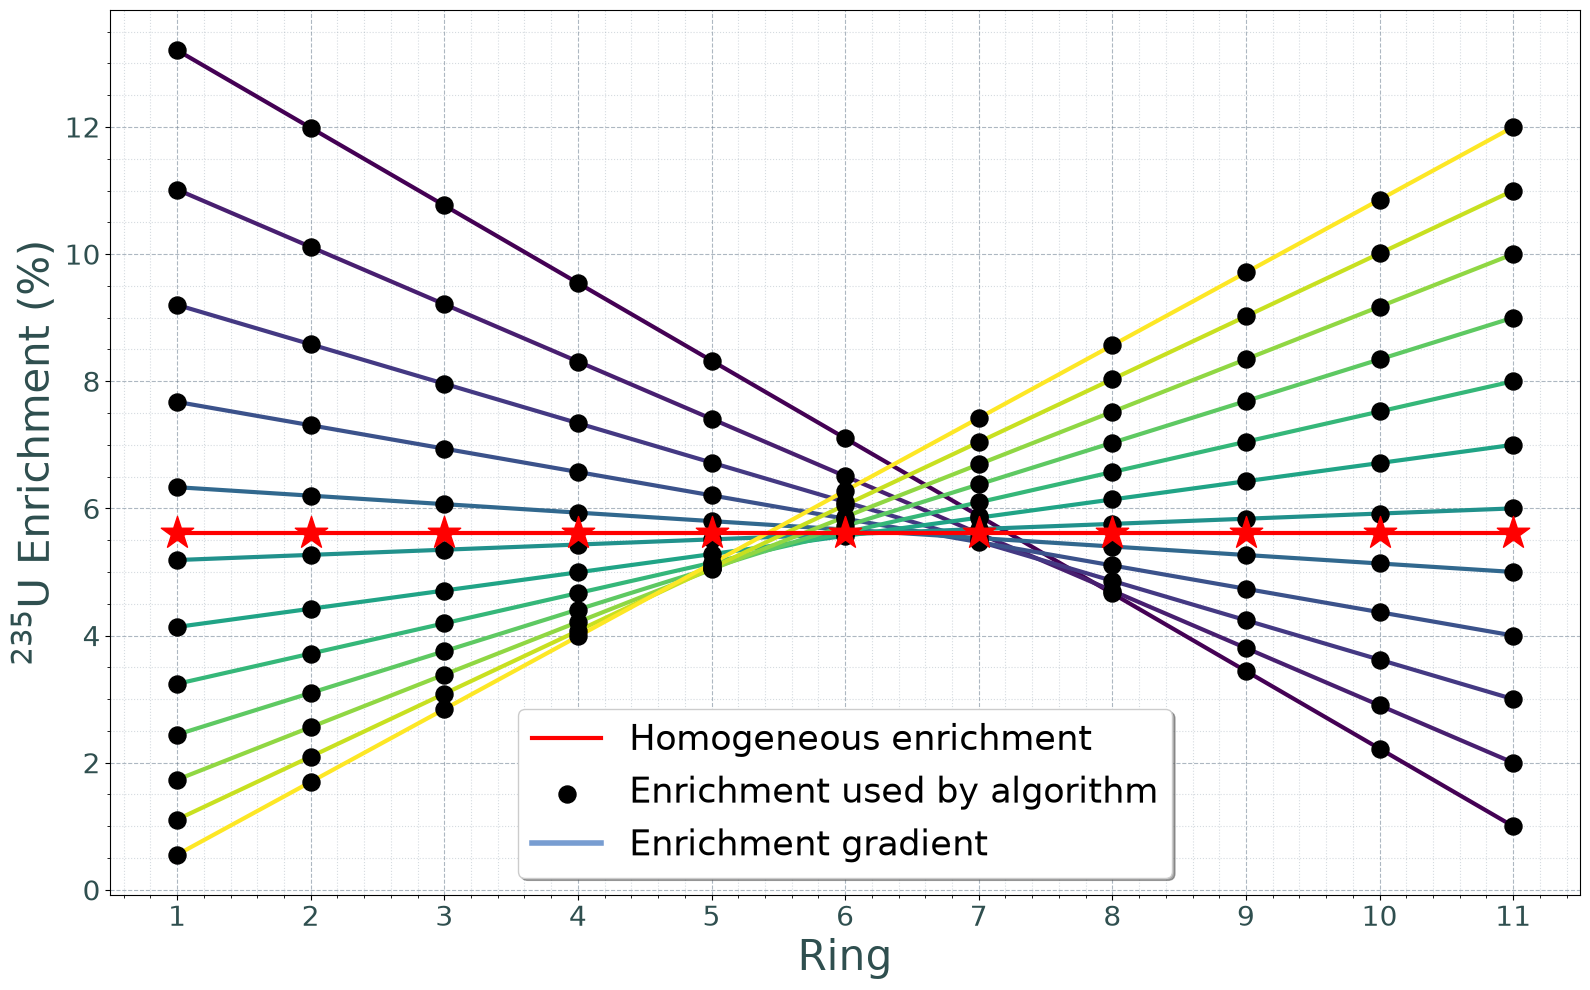

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.ticker as ticker

def plot_rette_filtrate(file_path, num_rings=13, n_rings_removed=2):
    """
    Traccia il profilo di arricchimento radiale basato sulla geometria fisica.
    Legge i valori x_pred (Arricch_EXT) e y_pred (Arricch_INT) da file.
    Evidenzia in rosso la retta ad arricchimento omogeneo.
    """
    print("### --- Analisi Rette --- ###\n")
    
    # Definizione delle colonne in base alla struttura del file
    nomi_colonne = [
        'Pres', 'moltiplicatore', 'PERC_water', 'Arricch_INT',
        'Arricch_EXT', 'T_WATER', 'T_FUEL', 'K_max', 'std_k_max',
        'K_auto', 'std_k_auto', 'Compatibilità'
    ]
    
    # Lettura del file saltando le prime 3 righe di intestazione
    df = pd.read_csv(file_path, sep=r'\s+', skiprows=3, names=nomi_colonne, engine='python')
    
    # Estrazione degli array
    x_pred = df['Arricch_EXT'].values
    y_pred = df['Arricch_INT'].values
    
    fig, ax = plt.subplots(figsize=(16, 10))
    media_vect = []
    
    # Array degli anelli fisicamente presenti nel nocciolo (partendo da 1)
    x_discrete_phys = np.arange(n_rings_removed, num_rings)
    x_discrete_plot = x_discrete_phys - n_rings_removed + 1
    colors = cm.viridis(np.linspace(0, 1, len(x_pred)))
    
    homo_label_added = False # Flag per evitare duplicati in legenda
    
    for i, (a_ext, a_int) in enumerate(zip(x_pred, y_pred)):
        
        # Calcolo coefficienti retta teorica: y = m*x + q
        m = (a_ext - a_int) / (num_rings - 1)
        q = a_int
        
        # Valutazione della retta SOLO sui pin discreti reali/attivi
        y_discrete = m * x_discrete_phys + q
        media_y = np.mean(y_discrete)
        
        print(f"Retta {i} [Teorica: P(0, {a_int:.3f}) -> P({num_rings-1}, {a_ext:.3f})]: Media = {media_y:.3f}")
        media_vect.append(media_y)
        
        # Controllo logico per l'arricchimento omogeneo (valore interno uguale a quello esterno)
        is_homogeneous = np.isclose(a_ext, a_int, atol=1e-5)
        
        if is_homogeneous:
            line_color = '#FF0000'
            marker_color = '#FF0000'
            z_order_line = 6
            z_order_scatter = 7
            mark = '*'
            surf = 600
            label_line = 'Homogeneous enrichment' if not homo_label_added else None
            homo_label_added = True
        else:
            line_color = colors[i]
            marker_color = '#000000' # Nero puro per i punti standard come da tue regole
            z_order_line = 4
            mark = 'o'
            surf = 150
            z_order_scatter = 5
            label_line = None
            
        # Plot della retta e dei punti campionati
        ax.plot(x_discrete_plot, y_discrete, color=line_color, linestyle='-', linewidth=3, zorder=z_order_line, label=label_line)
        ax.scatter(x_discrete_plot, y_discrete, color=marker_color, marker=mark, s=surf, zorder=z_order_scatter)

    # Impostazione dei tick dell'asse X solo su valori interi
    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))

    # Formattazione assi (font 22, colore scuro, tratto normale, unità tra parentesi tonde)
    ax.set_xlabel('Ring', fontsize=30, color='#2F4F4F')
    ax.set_ylabel('$^{235}$U Enrichment (%)', fontsize=30, color='#2F4F4F')
    
    # Formattazione Tick (Major: 18, Minor: 12)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=20, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=15)
    
    # Griglia standard
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Aggiunta manuale degli elementi standard alla legenda (oltre a quello omogeneo gestito nel loop)
    ax.scatter([], [], color='#000000', s=150, label=f'Enrichment used by algorithm')
    ax.plot([], [], color='#789DD1', linestyle='-', linewidth=4, label='Enrichment gradient')
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=25, facecolor="#FFFFFF")

    plt.tight_layout()
    plt.savefig('rette_filtrate.png', dpi=300)
    plt.show()
    
    return np.array(x_pred), np.array(y_pred), np.array(media_vect)

# Chiamata alla funzione
x_pred, y_pred, media_vect = plot_rette_filtrate('../result_final.txt', num_rings=13, n_rings_removed=2)

### --- Analisi Massa Effettiva U-235 --- ###

Configurazione EXT=1.0%, INT=15.65% -> Massa U-235: 11.818 (kg)
Configurazione EXT=2.0%, INT=12.82% -> Massa U-235: 11.509 (kg)
Configurazione EXT=3.0%, INT=10.44% -> Massa U-235: 11.498 (kg)
Configurazione EXT=4.0%, INT= 8.41% -> Massa U-235: 11.714 (kg)
Configurazione EXT=5.0%, INT= 6.60% -> Massa U-235: 12.075 (kg)
Configurazione EXT=5.6%, INT= 5.61% -> Massa U-235: 12.368 (kg)
Configurazione EXT=6.0%, INT= 5.03% -> Massa U-235: 12.590 (kg)
Configurazione EXT=7.0%, INT= 3.56% -> Massa U-235: 13.179 (kg)
Configurazione EXT=8.0%, INT= 2.29% -> Massa U-235: 13.892 (kg)
Configurazione EXT=9.0%, INT= 1.13% -> Massa U-235: 14.681 (kg)
Configurazione EXT=10.0%, INT= 0.08% -> Massa U-235: 15.540 (kg)
Configurazione EXT=11.0%, INT=-0.87% -> Massa U-235: 16.464 (kg)
Configurazione EXT=12.0%, INT=-1.74% -> Massa U-235: 17.445 (kg)


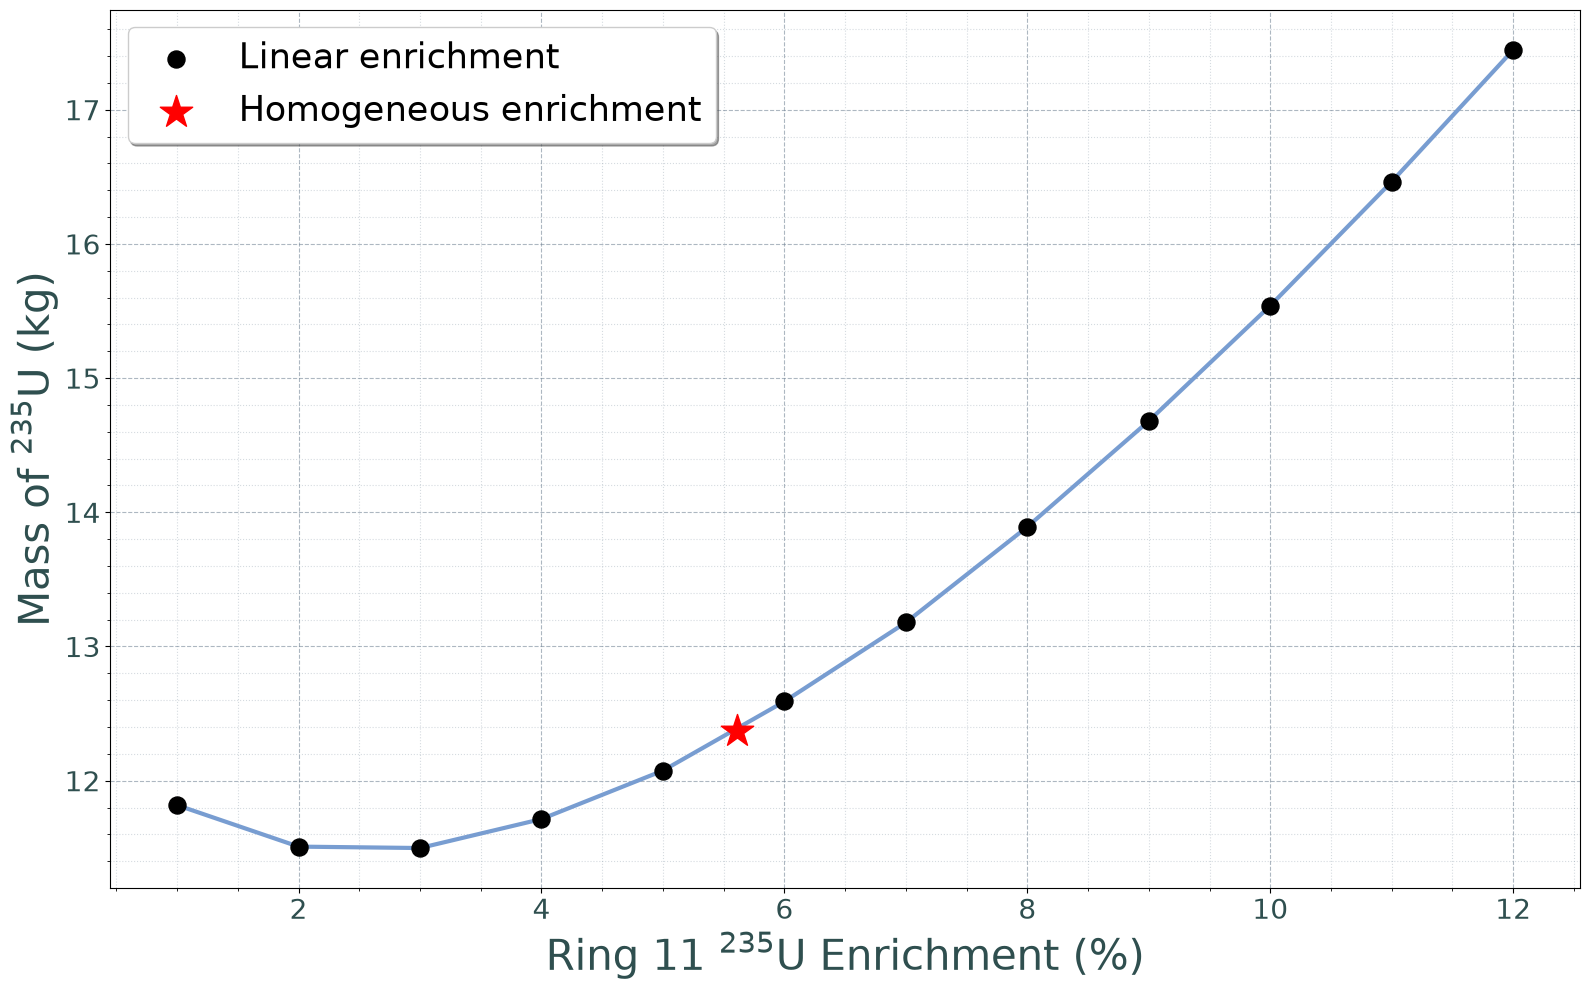

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def calcola_e_plotta_massa(file_path, num_rings=13, n_rings_removed=2, massa_u_tot_pin_g=477.28):
    """
    Calcola e traccia la massa effettiva di U-235 (kg) nel nocciolo in funzione
    dell'arricchimento esterno per le configurazioni subcritiche valide.
    Legge i valori da file ed evidenzia la configurazione ad arricchimento omogeneo.
    
    Parameters:
    -----------
    massa_u_tot_pin_g : float
        Massa totale di Uranio elementare contenuta in un singolo pin di combustibile (in grammi).
    """
    print("### --- Analisi Massa Effettiva U-235 --- ###\n")
    
    # Definizione delle colonne in base alla struttura del file
    nomi_colonne = [
        'Pres', 'moltiplicatore', 'PERC_water', 'Arricch_INT',
        'Arricch_EXT', 'T_WATER', 'T_FUEL', 'K_max', 'std_k_max',
        'K_auto', 'std_k_auto', 'Compatibilità'
    ]
    
    # Lettura del file saltando le prime 3 righe di intestazione
    df = pd.read_csv(file_path, sep=r'\s+', skiprows=3, names=nomi_colonne, engine='python')
    
    # Estrazione degli array
    x_pred = df['Arricch_EXT'].values
    y_pred = df['Arricch_INT'].values
    
    # Anelli fisicamente presenti nel nocciolo (da 2 a 13 inclusi)
    anelli = np.arange(n_rings_removed, num_rings)
    n_barre = 6 * anelli  # Numero di barre di combustibile per anello n
    
    valid_x = []
    mass_vect = []
    
    fig, ax = plt.subplots(figsize=(16, 10))
    
    # Liste separate per plottare i punti standard e quelli omogenei
    x_std, y_std = [], []
    x_homo, y_homo = [], []
    
    for i, (x_p, y_p) in enumerate(zip(x_pred, y_pred)):
        y_start = y_p  # Arricchimento teorico al centro (anello 0)
        y_end = x_p    # Arricchimento all'anello esterno (anello 13)
        
        # Pendenza del gradiente radiale: e_n = m * n + q
        m = (y_end - y_start) / (num_rings - 1)
        q = y_start
        
        # Arricchimenti valutati sugli anelli attivi (2-13) in percentuale (%)
        arricchimenti = m * anelli + q
        
        # Massa effettiva di U-235 in kg:
        # Somma(N_barre * (arricchimento_n / 100) * massa_u_tot_pin_g) / 1000
        massa_u235_kg = np.sum(n_barre * (arricchimenti / 100.0) * massa_u_tot_pin_g) / 1000.0
        
        valid_x.append(x_p)
        mass_vect.append(massa_u235_kg)
        print(f"Configurazione EXT={x_p:2.1f}%, INT={y_start:5.2f}% -> Massa U-235: {massa_u235_kg:.3f} (kg)")
        
        # Suddivisione logica per l'evidenziazione dell'arricchimento omogeneo
        if np.isclose(x_p, y_start, atol=1e-5):
            x_homo.append(x_p)
            y_homo.append(massa_u235_kg)
        else:
            x_std.append(x_p)
            y_std.append(massa_u235_kg)

    # Linea di tendenza generale calcolata su tutti i punti validi
    ax.plot(x_std, y_std, color='#789DD1', linestyle='-', linewidth=3, zorder=4)
    
    # Plot punti sperimentali standard (nero puro)
    if x_std:
        ax.scatter(x_std, y_std, color='#000000', s=150, zorder=5, label='Linear enrichment')
        
    # Plot del punto ad arricchimento omogeneo (rosso)
    if x_homo:
        ax.scatter(x_homo, y_homo, color='#FF0000', marker='*', s=600, zorder=6, label='Homogeneous enrichment')

    # Formattazione Assi (Font 22, nessun grassetto, colore grigio scuro)
    ax.set_xlabel('Ring 11 $^{235}$U Enrichment (%)', fontsize=30, color='#2F4F4F')
    ax.set_ylabel('Mass of $^{235}$U (kg)', fontsize=30, color='#2F4F4F')
    
    # Formattazione Tick (Major: 18, Minor: 12)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=20, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=15, labelcolor='#2F4F4F')
    
    # Setup della griglia
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    
    # Setup Legenda (loc='best', fontsize=25, sfondo Bianco)
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=25, facecolor="#FFFFFF")
    
    plt.tight_layout()
    plt.savefig('massa_effettiva_u235.png', dpi=300)
    plt.show()
    
    return np.array(valid_x), np.array(mass_vect)

# Esecuzione del calcolo leggendo direttamente dal file (impostando la massa U_tot del singolo pin in grammi)
x_val, massa_val = calcola_e_plotta_massa('../result_final.txt', massa_u_tot_pin_g=477.28)

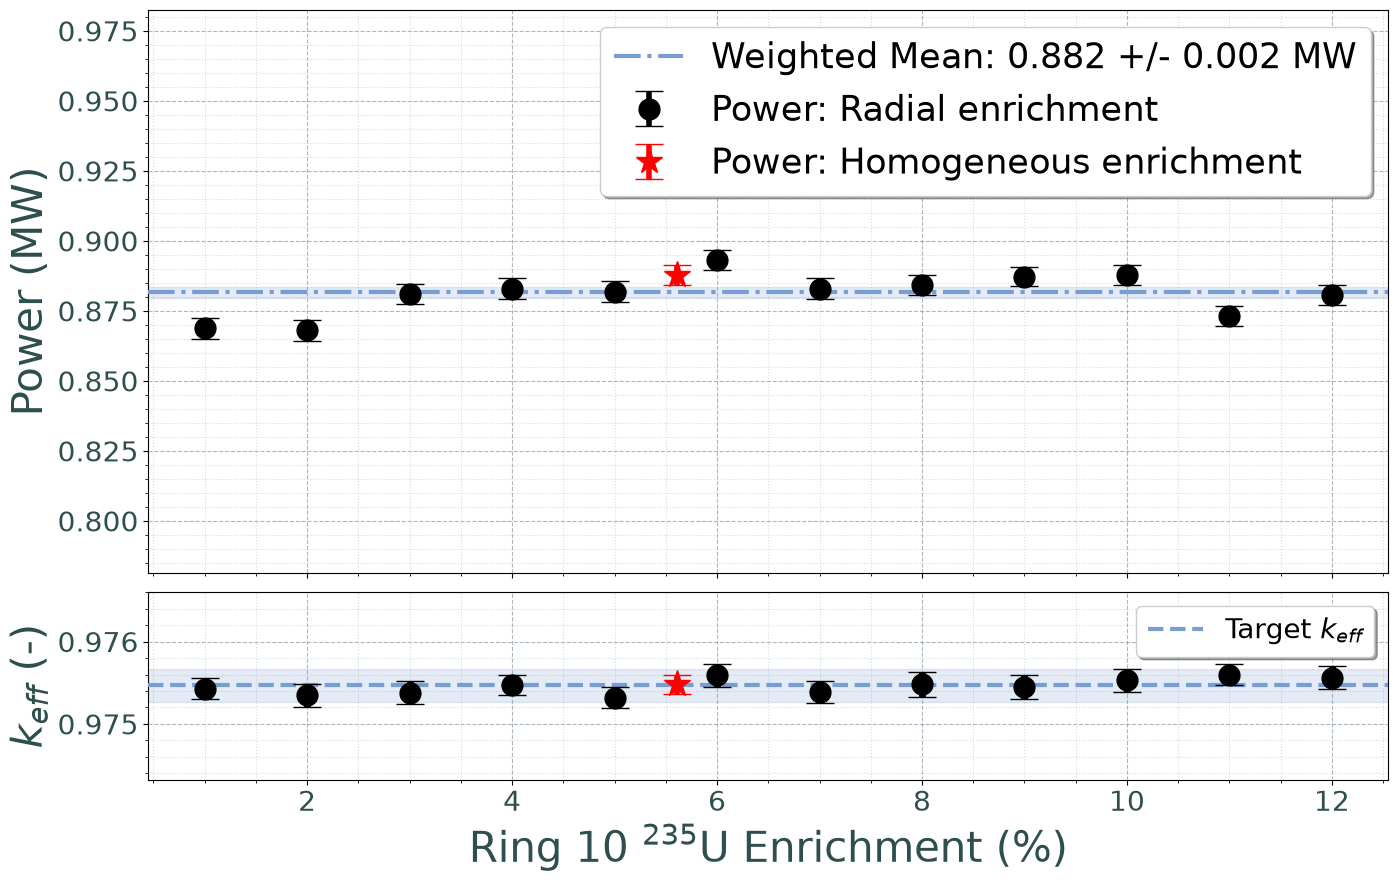

In [ ]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import openmc
import pandas as pd

# Costanti fisiche
E_FISSION_J = 200.0 * 1e6 * 1.6022e-19
S_INTENSITY = 2.02e17


def parse_result_final(filename):
    data = []
    with open(filename, "r") as file:
        for line in file:
            line = line.strip()
            if (
                not line
                or line.startswith("-")
                or line.startswith("=")
                or "Pres [Atm]" in line
            ):
                continue
            cols = line.split()
            if len(cols) == 12:
                try:
                    data.append(list(map(float, cols)))
                except ValueError:
                    continue
    columns = [
        "pressione_atm",
        "moltiplicatore",
        "perc_water",
        "arricch_INT",
        "arricch_EXT",
        "t_water",
        "t_fuel",
        "k_max",
        "std_k_max",
        "k_auto",
        "std_k_auto",
        "compatibilita",
    ]
    return pd.DataFrame(data, columns=columns)


def analizza_potenza():
    file_list = glob.glob("../fixed/statepoints/statepoint_arr_ext_*.h5")
    df_res = parse_result_final("../result_final.txt")

    if not file_list or df_res.empty:
        print("Dati mancanti (statepoints o result_final.txt).")
        return pd.DataFrame()

    dati = []
    # Pattern flessibile sia per interi che per float nell'arricchimento
    pattern = re.compile(r"statepoint_arr_ext_([\d\.]+)_pitch_([\d\.]+)\.h5")

    for file_sp in file_list:
        filename = os.path.basename(file_sp)
        match = pattern.search(filename)
        if not match:
            continue

        arr_ext = float(match.group(1))
        molt = float(match.group(2))

        # Filtraggio con tolleranza fissa per evitare mancati match sui float
        row = df_res[
            (np.isclose(df_res["arricch_EXT"], arr_ext, atol=1e-3))
            & (np.isclose(df_res["moltiplicatore"], molt, atol=1e-3))
        ]

        if row.empty:
            continue

        arr_int = row["arricch_INT"].values[0]
        k_sim = row["k_auto"].values[0]
        sigma_k_sim = row["std_k_auto"].values[0]
        k_ref = row["k_max"].values[0]
        sigma_k_ref = row["std_k_max"].values[0]

        with openmc.StatePoint(file_sp) as sp:
            try:
                tally = sp.get_tally(name="fission_tot")
                fission_mean = tally.mean.flatten()[0]
                fission_std = tally.std_dev.flatten()[0]
            except KeyError:
                continue

        p_sim = (fission_mean * S_INTENSITY * E_FISSION_J) / 1e6
        err_sim = (fission_std * S_INTENSITY * E_FISSION_J) / 1e6

        dati.append({
            "Arricchimento": arr_ext,
            "Arricch_INT": arr_int,
            "Moltiplicatore": molt,
            "Potenza_MW": p_sim,
            "Errore_MW": err_sim,
            "k_sim": k_sim,
            "err_k_sim": sigma_k_sim,
            "k_ref": k_ref,
            "err_k_ref": sigma_k_ref,
        })

    return pd.DataFrame(dati)


def plot_scatter_smooth_err(df):
    if df.empty:
        print("DataFrame vuoto: impossibile generare il plot.")
        return

    fig, (ax1, ax2) = plt.subplots(
        2,
        1,
        figsize=(16, 10),
        gridspec_kw={"height_ratios": [3, 1]},
        sharex=True,
    )

    moltiplicatori = df["Moltiplicatore"].unique()
    homo_label_added = False

    for m in moltiplicatori:
        # Ordinamento esplicito rispetto all'arricchimento esterno
        df_m = df[
            np.isclose(df["Moltiplicatore"], m, atol=1e-3)
        ].sort_values(by="Arricchimento")

        x = df_m["Arricchimento"].values
        arr_int = df_m["Arricch_INT"].values

        y_p = df_m["Potenza_MW"].values
        y_err_p = df_m["Errore_MW"].values

        y_k = df_m["k_sim"].values
        y_err_k = df_m["err_k_sim"].values

        # Maschera booleana robusta per il punto omogeneo
        mask_homo = np.isclose(x, arr_int, atol=1e-3)
        mask_std = ~mask_homo

        # ax1 (Potenza): Punti Standard (Nero)
        if np.any(mask_std):
            ax1.errorbar(
                x[mask_std],
                y_p[mask_std],
                yerr=y_err_p[mask_std],
                fmt="o",
                color="#000000",
                ecolor="#000000",
                elinewidth=4,
                capsize=10,
                zorder=5,
                markersize=15,
                label="Power: Radial enrichment" if not homo_label_added else None,
            )

        # ax1 (Potenza): Punti Omogenei (Rosso)
        if np.any(mask_homo):
            lbl = (
                "Power: Homogeneous enrichment" if not homo_label_added else None
            )
            ax1.errorbar(
                x[mask_homo],
                y_p[mask_homo],
                yerr=y_err_p[mask_homo],
                fmt="*",
                color="#FF0000",
                ecolor="#FF0000",
                elinewidth=4,
                capsize=10,
                zorder=6,
                markersize=20,
                label=lbl,
            )
            homo_label_added = True

        # ax2 (Fattore k): Punti Standard (Nero)
        if np.any(mask_std):
            ax2.errorbar(
                x[mask_std],
                y_k[mask_std],
                yerr=y_err_k[mask_std],
                fmt="o",
                color="#000000",
                ecolor="#000000",
                elinewidth=5,
                capsize=10,
                zorder=5,
                markersize=15,
            )

        # ax2 (Fattore k): Punti Omogenei (Rosso)
        if np.any(mask_homo):
            ax2.errorbar(
                x[mask_homo],
                y_k[mask_homo],
                yerr=y_err_k[mask_homo],
                fmt="*",
                color="#FF0000",
                ecolor="#FF0000",
                elinewidth=4,
                capsize=10,
                zorder=6,
                markersize=20,
            )

    # Analisi statistica globale (Media Pesata Potenza su ax1)
    pesi = 1.0 / (df["Errore_MW"] ** 2)
    media_pesata = np.sum(df["Potenza_MW"] * pesi) / np.sum(pesi)
    errore_media = 1.0 / np.sqrt(np.sum(pesi))
    chi_quadro = np.sum(
        ((df["Potenza_MW"] - media_pesata) ** 2) / (df["Errore_MW"] ** 2)
    )
    chi_ridotto = chi_quadro / (len(df) - 1) if len(df) > 1 else 1.0
    errore_media = errore_media * np.sqrt(max(1, chi_ridotto))

    ax1.axhline(
        y=media_pesata,
        color="#789DD1",
        linestyle="-.",
        linewidth=3,
        zorder=3,
        label=f"Weighted Mean: {media_pesata:.3f} +/- {errore_media:.3f} MW",
    )
    ax1.axhspan(
        ymin=media_pesata - errore_media,
        ymax=media_pesata + errore_media,
        color="#789DD1",
        alpha=0.2
    )

    # Linea k_ref (Target) su ax2
    k_target_mean = df["k_ref"].iloc[0]
    k_target_err = df["err_k_ref"].iloc[0]

    ax2.axhline(
        y=k_target_mean,
        color="#789DD1",
        linestyle="--",
        linewidth=3,
        zorder=3,
        label=r"Target $k_{eff}$",
    )
    ax2.axhspan(
        ymin=k_target_mean - k_target_err,
        ymax=k_target_mean + k_target_err,
        color="#789DD1",
        alpha=0.2,
        zorder=2,
    )

    # Formattazione Assi
    ax1.set_ylabel("Power (MW)", fontsize=30, color="#2F4F4F")
    ax2.set_xlabel(
        "Ring 11 $^{235}$U Enrichment (%)", fontsize=30, color="#2F4F4F"
    )
    ax2.set_ylabel(r"$k_{eff}$ (-)", fontsize=30, color="#2F4F4F")

    for ax in [ax1, ax2]:
        ax.minorticks_on()
        ax.tick_params(
            axis="both", which="major", labelsize=20, labelcolor="#2F4F4F"
        )
        ax.tick_params(axis="both", which="minor", labelsize=15)
        ax.grid(which="major", linestyle="--", alpha=0.6, color="#778899")
        ax.grid(which="minor", linestyle=":", alpha=0.3, color="#778899")

    ax1.legend(
        loc="best",
        frameon=True,
        shadow=True,
        fontsize=25,
        facecolor="#FFFFFF",
    )
    ax2.legend(
        loc="best",
        frameon=True,
        shadow=True,
        fontsize=20,
        facecolor="#FFFFFF",
    )

    ax1.set_ylim(df["Potenza_MW"].min() * 0.95, df["Potenza_MW"].max() * 1.05)
    ax2.set_ylim(
        df["k_sim"].min() - 0.001,
        max(df["k_sim"].max(), df["k_ref"].max()) + 0.001,
    )

    plt.subplots_adjust(hspace=0.05)
    plt.savefig('scatter_power_err.png', dpi=300)
    plt.show()


# Esecuzione
df_potenza = analizza_potenza()
plot_scatter_smooth_err(df_potenza)

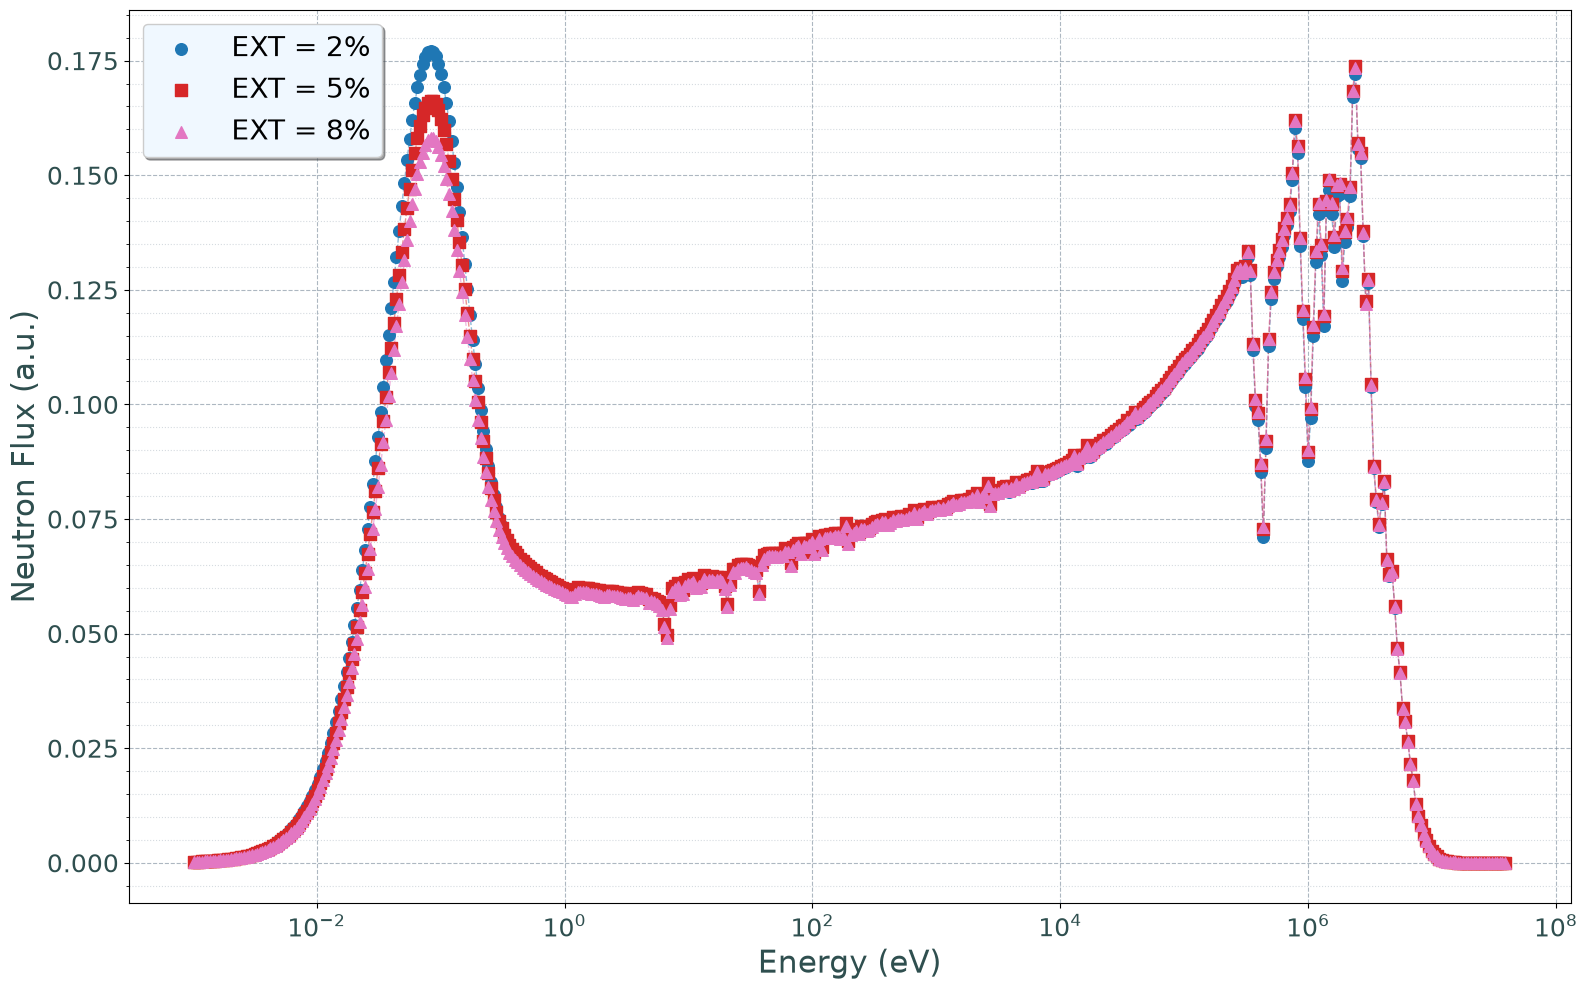

In [14]:
def plot_spettri_selezionati(arr_selezionati):
    """
    Traccia gli spettri neutronici energetici a punti discreti (scatter)
    per una selezione di arricchimenti esterni, con marcatori e colori distinti.
    """
    file_list = glob.glob("../fixed/statepoints/statepoint_arr_ext_*.h5")

    if not file_list:
        print("Nessun file statepoint trovato.")
        return

    # Regex robusta per decimali/interi
    pattern = re.compile(r"statepoint_arr_ext_([\d\.]+)_pitch_([\d\.]+)\.h5")

    # Configurazione della Figura (16, 10)
    fig, ax = plt.subplots(figsize=(16, 10))

    # Marcatori geometrici e Palette Colori
    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
    colors = cm.tab10(np.linspace(0, 1, len(arr_selezionati)))

    idx_style = 0

    for file_sp in sorted(file_list):
        filename = os.path.basename(file_sp)
        match = pattern.search(filename)

        if not match:
            continue

        arr_val = float(match.group(1))

        # Filtro: processiamo solo gli arricchimenti presenti nella lista desiderata
        if not any(np.isclose(arr_val, target) for target in arr_selezionati):
            continue

        with openmc.StatePoint(file_sp) as sp:
            try:
                # Estrazione tally dello spettro
                tally = sp.tallies[5]
                df = tally.get_pandas_dataframe()
            except (KeyError, AttributeError):
                continue

            neutrons = df[df['particle'] == 'neutron']

            E_low = neutrons['energy low [eV]'].values
            E_high = neutrons['energy high [eV]'].values

            # Media geometrica del bin energetico
            E_mid = np.sqrt(E_low * E_high)
            flux = neutrons['mean'].values

            marker = markers[idx_style % len(markers)]
            color = colors[idx_style % len(colors)]

            # Scatter plot per evidenziare la discretizzazione
            ax.scatter(
                E_mid, 
                flux, 
                color=color, 
                marker=marker, 
                s=70, 
                zorder=5, 
                label=f'EXT = {arr_val:.0f}%'
            )
            
            # Tratto leggero di congiunzione per seguire il profilo dello spettro
            ax.plot(
                E_mid, 
                flux, 
                color=color, 
                linestyle='--', 
                linewidth=1, 
                alpha=0.5, 
                zorder=4
            )

            idx_style += 1

    # Scala logaritmica sull'asse dell'energia
    ax.set_xscale('log')

    # Formattazione Assi (Font 22, nessun grassetto, unità tra tonde)
    ax.set_xlabel('Energy (eV)', fontsize=22, color='#2F4F4F')
    ax.set_ylabel('Neutron Flux (a.u.)', fontsize=22, color='#2F4F4F')

    # Formattazione Tick
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', labelsize=18, labelcolor='#2F4F4F')
    ax.tick_params(axis='both', which='minor', labelsize=12)

    # Setup della griglia avanzata
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')

    # Setup Legenda (loc='best', fontsize=20)
    ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')

    plt.tight_layout()
    plt.savefig('spettro_neutronico_discreto.png', dpi=300)
    plt.show()

# Esecuzione per la selezione desiderata (es. 0%, 2%, 5%, 8%, 10%)
plot_spettri_selezionati(arr_selezionati=[0, 2, 5, 8])

Il Peaking Factor (o fattore di picco) è un parametro adimensionale fondamentale nella fisica e nell'ingegneria dei reattori nucleari che misura la disomogeneità spaziale della distribuzione di potenza o di flusso neutronico all'interno del nocciolo12.In termini generali, definisce quanto il valore locale massimo di potenza si discosta dal valore medio dell'intero reattore:$$\text{Peaking Factor} = \frac{\text{Potenza Massima Locale (o di canale)}}{\text{Potenza Media del Nocciolo}}$$1. Perché è così importante per la sicurezza e la progettazione?In un reattore nucleare, la potenza termica totale prodotta (ad esempio $0.88\text{ MW}_{\text{th}}$ o $1500\text{ MW}_{\text{th}}$) è limitata dal punto più caldo del sistema (hot-spot)23.Limiti termoidraulici: Se in un voxel o in una fetta di combustibile la potenza prodotta per unità di volume ($\text{W/cm}^3$) o di lunghezza ($\text{W/cm}$) supera le soglie di tolleranza, la guaina (cladding) o le pastiglie di combustibile rischiano lo stress termico o la fusione3.Efficienza (Power Flattening): Più il Peaking Factor è vicino a $1$, più la potenza è "piatta" e uniforme34. Questo permette di estrarre più energia globale senza mai superare i vincoli di sicurezza locali3.2. I principali Peaking FactorsA seconda della direzione spaziale e della risoluzione considerata, si distinguono tre fattori di picco principali:A. $F_r$ — Peaking Factor RadialeMisura lo sbilanciamento della potenza sul piano trasversale $(x,y)$. $$F_r = \frac{\text{Potenza del canale/anello radiale più caldo}}{\text{Potenza radiale media}}$$ Nei reattori ADS (Accelerator-Driven Systems) con sorgente esterna al centro, il flusso neutronico tende ad avere un picco elevatissimo nella regione centrale23. Per questo motivo si adotta la strategia di fuel zoning (arricchimento radiale variabile), abbassando l'arricchimento al centro e alzandolo in periferia per appiattire la potenza radiale e ridurre $F_r$34.B. $F_z$ — Peaking Factor AssialeMisura lo sbilanciamento lungo l'altezza del nocciolo (asse $z$). $$F_z = \frac{\text{Potenza lineare massima } q' [\text{W/cm}]}{\text{Potenza lineare media } q' [\text{W/cm}]}$$ Solitamente segue il profilo di flusso assiale (spesso di forma cosinusoidale nei reattori omogenei, con picco sul piano medio $z = H/2$)5.C. $F_q$ — Peaking Factor Tridimensionale (Totale / Hot-Spot Factor)È il fattore di picco locale tridimensionale reale: $$F_q = \frac{\max P(x,y,z)}{\bar{P}_{\text{3D, core}}}$$ Confronta la potenza del singolo voxel 3D più caldo dell'intero nocciolo con la potenza media di tutti i voxel attivi. Se la distribuzione di potenza fosse perfettamente separabile nelle sue componenti radiale ed assiale ($P(x,y,z) = R(x,y) \cdot Z(z)$), si avrebbe $F_q \approx F_r \cdot F_z$. Nei reattori reali, $F_q$ tiene conto delle inclinazioni locali e delle deviazioni dalla separabilità ideale.

statepoint_arr_ext_10_pitch_1.h5 | Fr=2.406±0.027 | Fz=1.422±0.016 | Fq=3.238±0.036 | Homo=False
statepoint_arr_ext_11_pitch_1.h5 | Fr=2.414±0.027 | Fz=1.424±0.016 | Fq=3.268±0.037 | Homo=False
statepoint_arr_ext_12_pitch_1.h5 | Fr=2.417±0.027 | Fz=1.428±0.016 | Fq=3.257±0.037 | Homo=False
statepoint_arr_ext_1_pitch_1.h5 | Fr=2.608±0.027 | Fz=1.617±0.017 | Fq=4.604±0.048 | Homo=False
statepoint_arr_ext_2_pitch_1.h5 | Fr=2.563±0.027 | Fz=1.571±0.017 | Fq=4.346±0.046 | Homo=False
statepoint_arr_ext_3_pitch_1.h5 | Fr=2.523±0.026 | Fz=1.533±0.016 | Fq=4.102±0.043 | Homo=False
statepoint_arr_ext_4_pitch_1.h5 | Fr=2.489±0.027 | Fz=1.501±0.016 | Fq=3.885±0.042 | Homo=False
statepoint_arr_ext_5.609_pitch_1.h5 | Fr=2.451±0.027 | Fz=1.464±0.016 | Fq=3.616±0.039 | Homo=True
statepoint_arr_ext_5_pitch_1.h5 | Fr=2.471±0.027 | Fz=1.476±0.016 | Fq=3.703±0.040 | Homo=False
statepoint_arr_ext_6_pitch_1.h5 | Fr=2.444±0.026 | Fz=1.457±0.016 | Fq=3.527±0.038 | Homo=False
statepoint_arr_ext_7_pitch_1.h5 | 

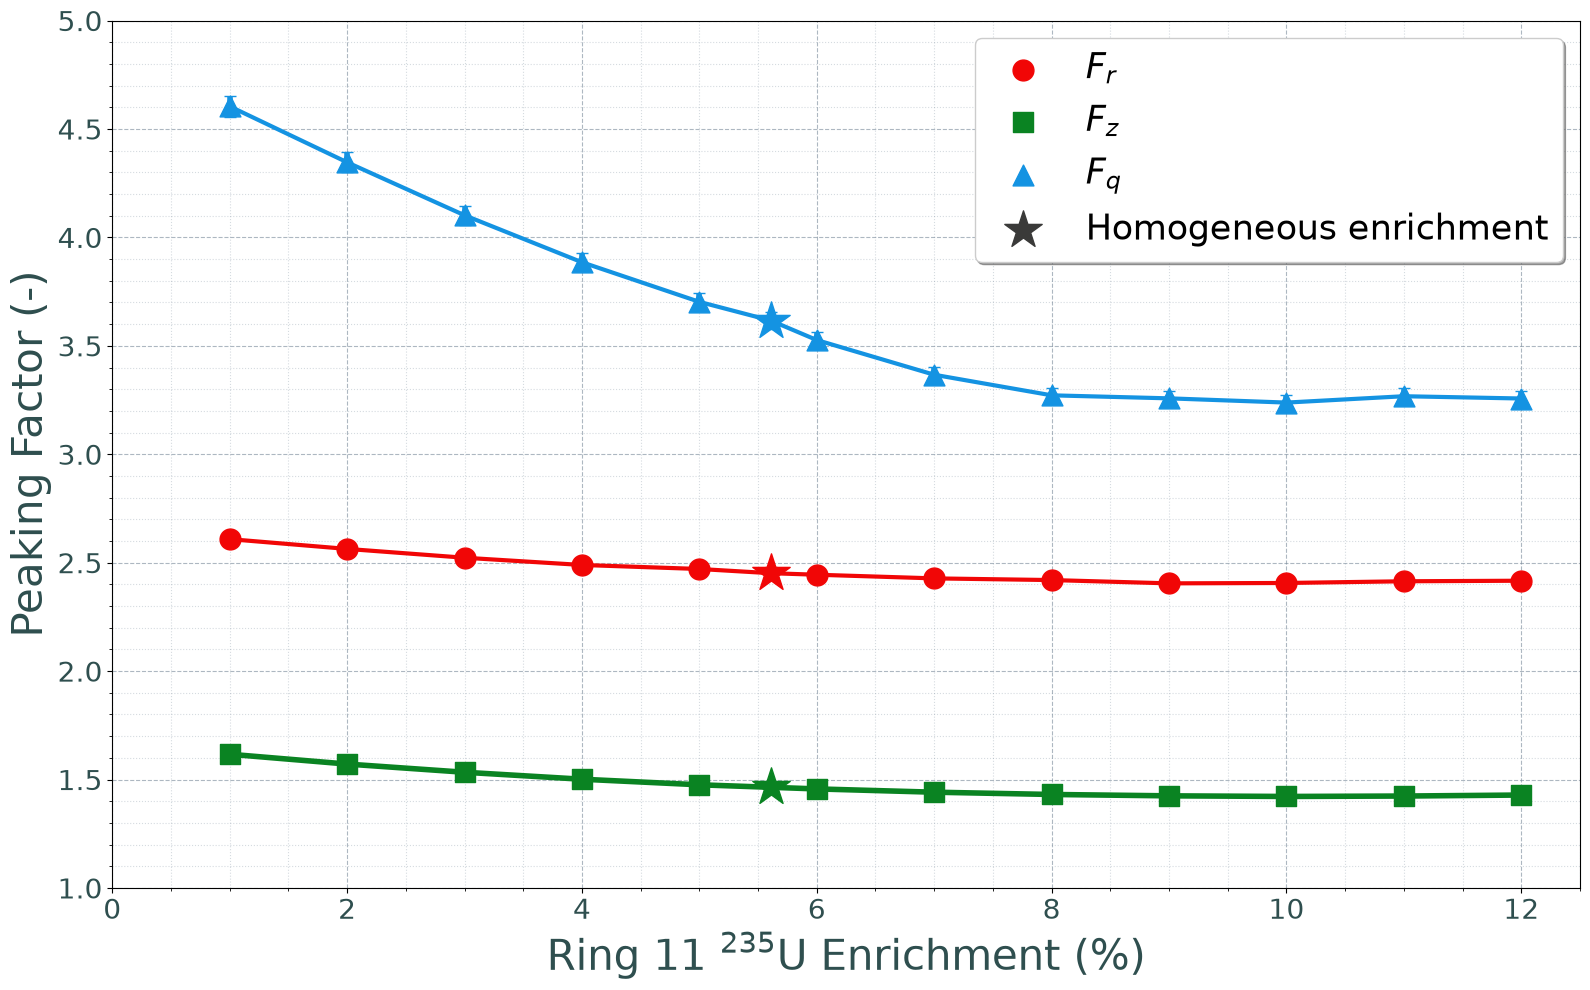

In [ ]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import openmc
import pandas as pd


def analizza_peaking():
    file_list = glob.glob("../fixed/statepoints/statepoint_arr_ext_*.h5")
    # Pattern aggiornato per supportare sia interi che decimali
    pattern = re.compile(r"statepoint_arr_ext_([\d\.]+)_pitch_([\d\.]+)\.h5")

    # Lettura di result_final.txt per identificare quale arricchimento è omogeneo
    nomi_colonne = [
        "Pres",
        "moltiplicatore",
        "PERC_water",
        "Arricch_INT",
        "Arricch_EXT",
        "T_WATER",
        "T_FUEL",
        "K_max",
        "std_k_max",
        "K_auto",
        "std_k_auto",
        "Compatibilità",
    ]
    try:
        df_res = pd.read_csv(
            "../result_final.txt",
            sep=r"\s+",
            skiprows=3,
            names=nomi_colonne,
            engine="python",
        )
    except FileNotFoundError:
        print(
            "File ../result_final.txt non trovato. Impossibile identificare"
            " punto omogeneo."
        )
        df_res = pd.DataFrame()

    dati = []

    for file_sp in sorted(file_list):
        filename = os.path.basename(file_sp)
        match = pattern.search(filename)
        if not match:
            continue

        arricchimento = float(match.group(1))
        moltiplicatore = float(match.group(2))

        # Controllo arricchimento omogeneo (Arricch_INT == Arricch_EXT)
        is_homo = False
        if not df_res.empty:
            row = df_res[
                (np.isclose(df_res["Arricch_EXT"], arricchimento, atol=1e-3))
                & (
                    np.isclose(
                        df_res["moltiplicatore"], moltiplicatore, atol=1e-3
                    )
                )
            ]
            if not row.empty:
                arr_int = row["Arricch_INT"].values[0]
                is_homo = np.isclose(arricchimento, arr_int, atol=1e-3)

        try:
            with openmc.StatePoint(file_sp) as sp:
                tally = sp.get_tally(name="tally_3d_power")
                mean = tally.mean[:, 0, 1].flatten()
                std = tally.std_dev[:, 0, 1].flatten()
                mesh = tally.filters[0].mesh
                nx, ny, nz = mesh.dimension
                mean = mean.reshape((nx, ny, nz))
                std = std.reshape((nx, ny, nz))

                # ------------------------------
                # Calcolo errore relativo medio
                # ------------------------------
                mask = mean > 0
                if np.sum(mask) == 0:
                    print(f"{filename}: tutti valori nulli")
                    continue

                rel_err = np.mean(std[mask] / mean[mask])

                # ------------------------------
                # Fq
                # ------------------------------
                Fq = mean.max() / mean.mean()
                err_Fq = Fq * rel_err

                # ------------------------------
                # Fr
                # ------------------------------
                power_xy = mean.sum(axis=2)
                Fr = power_xy.max() / power_xy.mean()
                err_Fr = Fr * rel_err

                # ------------------------------
                # Fz
                # ------------------------------
                power_z = mean.sum(axis=(0, 1))
                Fz = power_z.max() / power_z.mean()
                err_Fz = Fz * rel_err

                dati.append({
                    "Arricchimento": arricchimento,
                    "Moltiplicatore": moltiplicatore,
                    "Fr": Fr,
                    "Fr_err": err_Fr,
                    "Fz": Fz,
                    "Fz_err": err_Fz,
                    "Fq": Fq,
                    "Fq_err": err_Fq,
                    "FrFz": Fr * Fz,
                    "is_homo": is_homo,
                })

                print(
                    f"{filename} | Fr={Fr:.3f}±{err_Fr:.3f} |"
                    f" Fz={Fz:.3f}±{err_Fz:.3f} | Fq={Fq:.3f}±{err_Fq:.3f} |"
                    f" Homo={is_homo}"
                )

        except Exception as e:
            print(f"Errore in {filename}")
            print(e)

    return pd.DataFrame(dati)


# =====================================================
# ELABORAZIONE
# =====================================================

df_peak = analizza_peaking()
df_peak = df_peak.sort_values("Arricchimento")

# Separazione punti standard vs omogenei
df_std = df_peak[df_peak["is_homo"] == False]
df_homo = df_peak[df_peak["is_homo"] == True]

# =====================================================
# PLOT
# =====================================================

fig, ax = plt.subplots(figsize=(16, 10))

# Definizione stili per ciascuna grandezza
stili = {
    "Fr": {"color": "#F10606", "fmt": "o", "label": r"$F_r$ (radial)"},
    "Fz": {"color": "#0A8322", "fmt": "s", "label": r"$F_z$ (axial)"},
    "Fq": {"color": "#1493E2", "fmt": "^", "label": r"$F_q$ (total)"},
}

for col, s in stili.items():
    err_col = f"{col}_err"

    # 1. Tracciamento della linea continua e delle barre d'errore su TUTTI i punti
    ax.plot(
        df_peak["Arricchimento"],
        df_peak[col],
        color=s["color"],
        linewidth=3 if col != "Fz" else 4,
        zorder=4,
    )
    ax.errorbar(
        df_peak["Arricchimento"],
        df_peak[col],
        yerr=df_peak[err_col],
        fmt="none",
        ecolor=s["color"],
        capsize=4,
        elinewidth=4,
        zorder=4,
    )

    # 2. Scatter dei soli punti STANDARD (cerchi/quadrati/triangoli)
    if not df_std.empty:
        ax.scatter(
            df_std["Arricchimento"],
            df_std[col],
            marker=s["fmt"],
            color=s["color"],
            s=225,  # equivalente a markersize=15
            zorder=5,
            label=s["label"],
        )

    # 3. Scatter dei soli punti OMOGENEI (esclusivamente stella)
    if not df_homo.empty:
        ax.scatter(
            df_homo["Arricchimento"],
            df_homo[col],
            marker="*",
            color=s["color"],
            s=800,
            zorder=6,
            edgecolors=s["color"],
            linewidths=1,
        )

# Segnaposto fittizio per l'ingresso in legenda della stella omogenea
if not df_homo.empty:
    ax.scatter(
        [],
        [],
        marker="*",
        color="#3A3A39",
        s=800,
        zorder=6,
        edgecolors="#3A3A39",
        linewidths=1,
        label="Homogeneous enrichment",
    )

# Formattazione Assi
ax.set_xlabel(
    "Ring 11 $^{235}$U Enrichment (%)", fontsize=30, color="#2F4F4F"
)
ax.set_ylabel("Peaking Factor (-)", fontsize=30, color="#2F4F4F")

# Formattazione Tick
ax.minorticks_on()
ax.tick_params(
    axis="both", which="major", labelsize=20, labelcolor="#2F4F4F"
)
ax.tick_params(axis="both", which="minor", labelsize=15)

# Setup della griglia avanzata
ax.grid(which="major", linestyle="--", alpha=0.6, color="#778899")
ax.grid(which="minor", linestyle=":", alpha=0.3, color="#778899")

ax.set_xlim(0, 12.5)
ax.set_ylim(1, 5)

# Setup Legenda
ax.legend(
    loc="best",
    frameon=True,
    shadow=True,
    fontsize=25,
    facecolor="#FFFFFF",
)

plt.tight_layout()
plt.savefig("peaking_factors.png", dpi=300)
plt.show()

analizzo solo il ramo di sinistra delle parabole perchè in quello di destra le configurazioni peggiorano sempre, non può essere lì l'ottimo allora

uso quindi normalizzazione tra massimo e minimo del ramo SX per normalizzare i dati e plottare. il più vicino all'orgigine rappresenta il best configuration

--> metodo di pareto


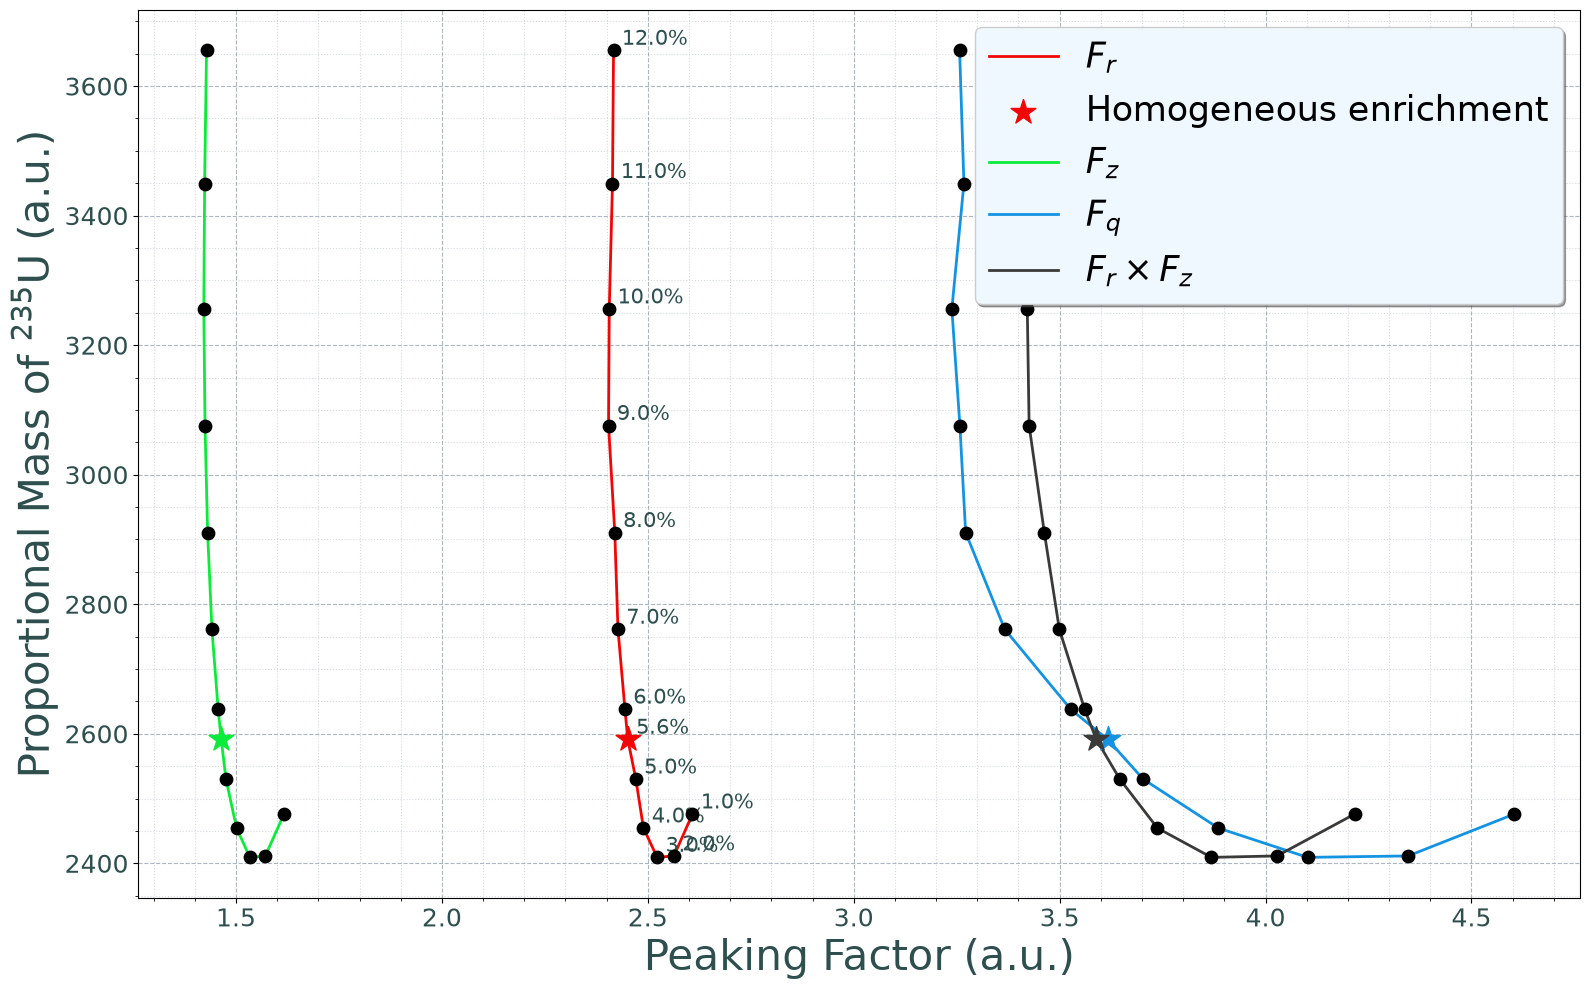

In [16]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import openmc
import pandas as pd

# =====================================================
# 1. ESTRAZIONE PEAKING FACTORS 
# =====================================================
def analizza_peaking():
    file_list = glob.glob("../fixed/statepoints/statepoint_arr_ext_*.h5")
    pattern = re.compile(r"statepoint_arr_ext_([\d\.]+)_pitch_([\d\.]+)\.h5")

    nomi_colonne = [
        "Pres", "moltiplicatore", "PERC_water", "Arricch_INT",
        "Arricch_EXT", "T_WATER", "T_FUEL", "K_max", "std_k_max",
        "K_auto", "std_k_auto", "Compatibilità",
    ]
    try:
        df_res = pd.read_csv(
            "../result_final.txt", sep=r"\s+", skiprows=3, names=nomi_colonne, engine="python"
        )
    except FileNotFoundError:
        print("File ../result_final.txt non trovato.")
        df_res = pd.DataFrame()

    dati = []

    for file_sp in sorted(file_list):
        filename = os.path.basename(file_sp)
        match = pattern.search(filename)
        if not match:
            continue

        arricchimento = float(match.group(1))
        moltiplicatore = float(match.group(2))

        is_homo = False
        if not df_res.empty:
            row = df_res[
                (np.isclose(df_res["Arricch_EXT"], arricchimento, atol=1e-3))
                & (np.isclose(df_res["moltiplicatore"], moltiplicatore, atol=1e-3))
            ]
            if not row.empty:
                arr_int = row["Arricch_INT"].values[0]
                is_homo = np.isclose(arricchimento, arr_int, atol=1e-3)

        try:
            with openmc.StatePoint(file_sp) as sp:
                tally = sp.get_tally(name="tally_3d_power")
                mean = tally.mean[:, 0, 1].flatten()
                std = tally.std_dev[:, 0, 1].flatten()
                mesh = tally.filters[0].mesh
                nx, ny, nz = mesh.dimension
                mean = mean.reshape((nx, ny, nz))
                std = std.reshape((nx, ny, nz))

                mask = mean > 0
                if np.sum(mask) == 0:
                    continue

                rel_err = np.mean(std[mask] / mean[mask])

                Fq = mean.max() / mean.mean()
                err_Fq = Fq * rel_err

                power_xy = mean.sum(axis=2)
                Fr = power_xy.max() / power_xy.mean()
                err_Fr = Fr * rel_err

                power_z = mean.sum(axis=(0, 1))
                Fz = power_z.max() / power_z.mean()
                err_Fz = Fz * rel_err

                dati.append({
                    "Arricchimento": arricchimento,
                    "Moltiplicatore": moltiplicatore,
                    "Fr": Fr, "Fr_err": err_Fr,
                    "Fz": Fz, "Fz_err": err_Fz,
                    "Fq": Fq, "Fq_err": err_Fq,
                    "FrFz": Fr * Fz,
                    "is_homo": is_homo,
                })
        except Exception as e:
            continue

    return pd.DataFrame(dati)

# =====================================================
# 2. CALCOLO MASSA, MERGE E PLOT COMBINATO
# =====================================================
df_peak = analizza_peaking()

# Lettura file per ricavare la massa di ogni configurazione
nomi_colonne = [
    "Pres", "moltiplicatore", "PERC_water", "Arricch_INT", "Arricch_EXT",
    "T_WATER", "T_FUEL", "K_max", "std_k_max", "K_auto", "std_k_auto", "Compatibilità"
]
df_res = pd.read_csv('../result_final.txt', sep=r'\s+', skiprows=3, names=nomi_colonne, engine='python')

# Parametri geometrici per il calcolo della massa
num_rings = 13
n_rings_removed = 2
anelli = np.arange(n_rings_removed, num_rings)
n_barre = 6 * anelli

# Calcolo massa vettoriale per ogni riga in df_res
masse = []
for _, row in df_res.iterrows():
    y_start = row['Arricch_INT']
    y_end = row['Arricch_EXT']
    m = (y_end - y_start) / (num_rings - 1)
    q = y_start
    arricchimenti = m * anelli + q
    masse.append(np.sum(n_barre * arricchimenti))

df_res['Massa_Prop'] = masse

# Merge robusto tramite arrotondamento dell'arricchimento esterno
df_peak['Arricch_EXT_merge'] = df_peak['Arricchimento'].round(3)
df_res['Arricch_EXT_merge'] = df_res['Arricch_EXT'].round(3)

df_plot = pd.merge(df_peak, df_res[['Arricch_EXT_merge', 'Massa_Prop']], on='Arricch_EXT_merge', how='inner')

# FONDAMENTALE: Ordinamento per Arricchimento Esterno crescente
# In questo modo la spezzata segue l'andamento fisico (0% -> 1% -> 2% ... -> 13%)
df_plot = df_plot.sort_values(by='Arricchimento').reset_index(drop=True)

# Generazione Plot
fig, ax = plt.subplots(figsize=(16, 10))

# Configurazione Curve: (Colonna DataFrame, Etichetta Legenda, Colore)
curve_config = [
    ("Fr", r"$F_r$", "#F10606"),
    ("Fz", r"$F_z$", "#0CEB39"),
    ("Fq", r"$F_q$", "#1493E2"),
    ("FrFz", r"$F_r \times F_z$", "#3A3A39")
]

y_data = df_plot["Massa_Prop"].values
is_homo_vec = df_plot["is_homo"].values
ext_vec = df_plot["Arricchimento"].values
homo_label_added = False

for col, label_text, color_line in curve_config:
    x_data = df_plot[col].values
    
    # 1. Tracciamento linea continua ordinata per arricchimento
    ax.plot(x_data, y_data, color=color_line, linestyle="-", linewidth=2, zorder=3, label=label_text)
    
    # 2. Marker standard (Nero puro)
    mask_s = ~is_homo_vec
    if np.any(mask_s):
        ax.scatter(x_data[mask_s], y_data[mask_s], color="#000000", s=80, zorder=4)
        
    # 3. Marker Omogeneo (Stella colorata in base alla curva)
    mask_h = is_homo_vec
    if np.any(mask_h):
        lbl_h = "Homogeneous enrichment" if not homo_label_added else None
        ax.scatter(
            x_data[mask_h], y_data[mask_h], 
            marker="*", color=color_line, s=350, 
            zorder=5, edgecolors=color_line, linewidths=1, label=lbl_h
        )
        homo_label_added = True

# Aggiunta annotazioni percentuali
# Usiamo i valori x della prima curva (Fr) come riferimento per l'annotazione
for x_val, y_val, ext_val in zip(df_plot["Fr"].values, y_data, ext_vec):
    ax.annotate(
        f"{ext_val:.1f}%", 
        xy=(x_val, y_val), 
        textcoords="offset points", 
        xytext=(6, 4), 
        fontsize=15, 
        color="#2F4F4F"
    )

# Formattazione rigorosa degli Assi
ax.set_xlabel("Peaking Factor (a.u.)", fontsize=30, color="#2F4F4F")
ax.set_ylabel("Proportional Mass of $^{235}$U (a.u.)", fontsize=30, color="#2F4F4F")

ax.minorticks_on()
ax.tick_params(axis="both", which="major", labelsize=18, labelcolor="#2F4F4F")
ax.tick_params(axis="both", which="minor", labelsize=12)

ax.grid(which="major", linestyle="--", alpha=0.6, color="#778899")
ax.grid(which="minor", linestyle=":", alpha=0.3, color="#778899")

ax.legend(loc="best", frameon=True, shadow=True, fontsize=25, facecolor="#F0F8FF")

plt.tight_layout()
plt.show()

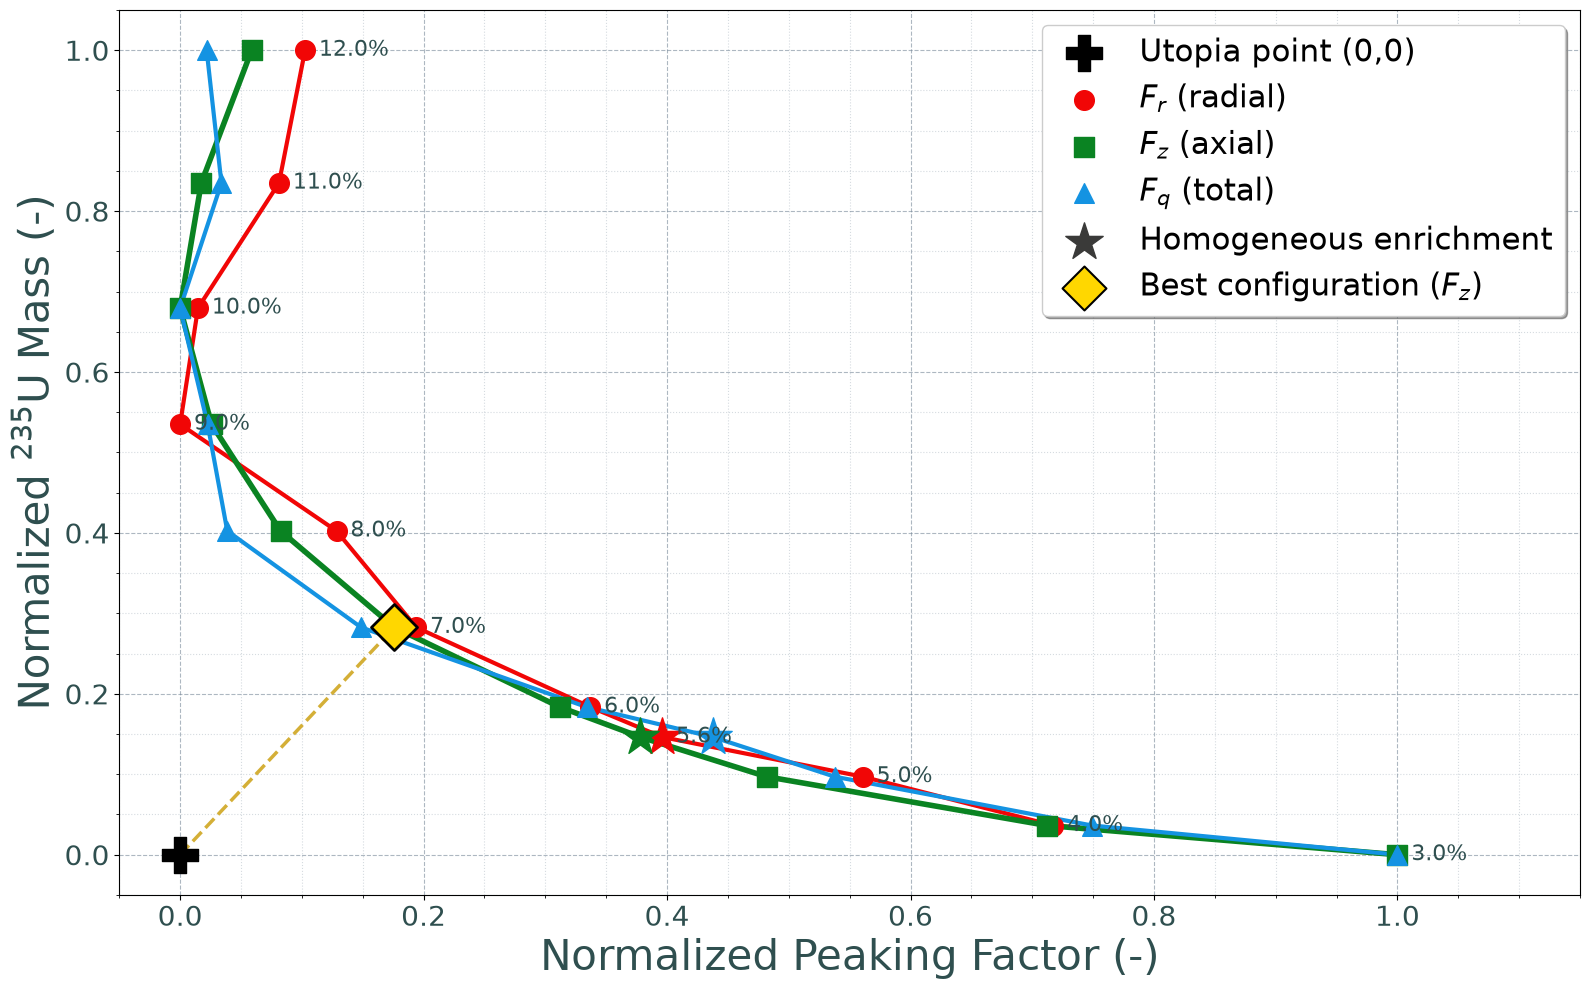

In [ ]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import openmc
import pandas as pd


def analizza_peaking_e_massa(
    lato_esag_cm=0.5, h_attiva_cm=80.0, rho_uo2_g_cm3=10.42
):
    """Calcola Peaking Factor da OpenMC e massa di U-235 per pin esagonale."""
    area_esag_cm2 = (3 * np.sqrt(3) / 2) * (lato_esag_cm**2)
    volume_pin_cm3 = area_esag_cm2 * h_attiva_cm
    massa_uo2_pin_g = volume_pin_cm3 * rho_uo2_g_cm3
    frazione_u = 238.03 / (238.03 + 2 * 15.999)
    massa_u_tot_pin_g = massa_uo2_pin_g * frazione_u

    num_rings = 13
    n_rings_removed = 2
    anelli = np.arange(n_rings_removed, num_rings)
    n_barre = 6 * anelli

    file_list = glob.glob("../fixed/statepoints/statepoint_arr_ext_*.h5")
    pattern = re.compile(r"statepoint_arr_ext_([\d\.]+)_pitch_([\d\.]+)\.h5")

    nomi_colonne = [
        "Pres", "moltiplicatore", "PERC_water", "Arricch_INT",
        "Arricch_EXT", "T_WATER", "T_FUEL", "K_max", "std_k_max",
        "K_auto", "std_k_auto", "Compatibilità",
    ]

    try:
        df_res = pd.read_csv(
            "../result_final.txt",
            sep=r"\s+",
            skiprows=3,
            names=nomi_colonne,
            engine="python",
        )
    except FileNotFoundError:
        print("File ../result_final.txt non trovato.")
        df_res = pd.DataFrame()

    dati = []

    for file_sp in sorted(file_list):
        filename = os.path.basename(file_sp)
        match = pattern.search(filename)
        if not match:
            continue

        arricchimento = float(match.group(1))
        moltiplicatore = float(match.group(2))

        # Filtraggio esplicito: solo arricchimenti > 2%
        if arricchimento <= 2.0:
            continue

        is_homo = False
        arr_int = arricchimento

        if not df_res.empty:
            row = df_res[
                (np.isclose(df_res["Arricch_EXT"], arricchimento, atol=1e-3))
                & (
                    np.isclose(
                        df_res["moltiplicatore"], moltiplicatore, atol=1e-3
                    )
                )
            ]
            if not row.empty:
                arr_int = row["Arricch_INT"].values[0]
                is_homo = np.isclose(arricchimento, arr_int, atol=1e-3)

        # Calcolo massa effettiva U-235 (kg)
        m_grad = (arricchimento - arr_int) / (num_rings - 1)
        q_grad = arr_int
        arricchimenti_anelli = m_grad * anelli + q_grad
        massa_u235_kg = (
            np.sum(n_barre * (arricchimenti_anelli / 100.0) * massa_u_tot_pin_g)
            / 1000.0
        )

        try:
            with openmc.StatePoint(file_sp) as sp:
                tally = sp.get_tally(name="tally_3d_power")
                mean = tally.mean[:, 0, 1].flatten()
                std = tally.std_dev[:, 0, 1].flatten()
                mesh = tally.filters[0].mesh
                nx, ny, nz = mesh.dimension
                mean = mean.reshape((nx, ny, nz))
                std = std.reshape((nx, ny, nz))

                mask = mean > 0
                if np.sum(mask) == 0:
                    continue

                rel_err = np.mean(std[mask] / mean[mask])

                Fq = mean.max() / mean.mean()
                err_Fq = Fq * rel_err

                power_xy = mean.sum(axis=2)
                Fr = power_xy.max() / power_xy.mean()
                err_Fr = Fr * rel_err

                power_z = mean.sum(axis=(0, 1))
                Fz = power_z.max() / power_z.mean()
                err_Fz = Fz * rel_err

                dati.append({
                    "Massa_U235_kg": massa_u235_kg,
                    "Arricchimento": arricchimento,
                    "Fr": Fr,
                    "Fr_err": err_Fr,
                    "Fz": Fz,
                    "Fz_err": err_Fz,
                    "Fq": Fq,
                    "Fq_err": err_Fq,
                    "is_homo": is_homo,
                })

        except Exception as e:
            print(f"Errore in {filename}: {e}")

    return pd.DataFrame(dati)


# =====================================================
# ELABORAZIONE DATO E NORMALIZZAZIONE
# =====================================================

df_peak = analizza_peaking_e_massa()
df_peak = df_peak.sort_values("Massa_U235_kg")

# Normalizzazione Min-Max in [0, 1] per la Massa
m_min, m_max = df_peak["Massa_U235_kg"].min(), df_peak["Massa_U235_kg"].max()
df_peak["Massa_norm"] = (df_peak["Massa_U235_kg"] - m_min) / (m_max - m_min)

# Normalizzazione e Calcolo Distanza Euclidea dall'Utopia Point (0,0) per ciascun Peaking Factor
stili = {
    "Fr": {"color": "#F10606", "fmt": "o", "label": r"$F_r$ (radial)"},
    "Fz": {"color": "#0A8322", "fmt": "s", "label": r"$F_z$ (axial)"},
    "Fq": {"color": "#1493E2", "fmt": "^", "label": r"$F_q$ (total)"},
}

for col in stili.keys():
    f_min, f_max = df_peak[col].min(), df_peak[col].max()
    df_peak[f"{col}_norm"] = (df_peak[col] - f_min) / (f_max - f_min)
    # Distanza euclidea dall'origine (0,0)
    df_peak[f"{col}_dist"] = np.sqrt(
        df_peak[f"{col}_norm"] ** 2 + df_peak["Massa_norm"] ** 2
    )

# =====================================================
# PLOT PARETO
# =====================================================

fig, ax = plt.subplots(figsize=(16, 10))

# 1. Segna l'Utopia Point nell'Origine (0,0)
ax.scatter(
    0,
    0,
    color="#000000",
    marker="P",
    s=700,
    zorder=10,
    label="Utopia point (0,0)",
)

df_std = df_peak[df_peak["is_homo"] == False]
df_homo = df_peak[df_peak["is_homo"] == True]

for col, s in stili.items():
    col_norm = f"{col}_norm"
    col_dist = f"{col}_dist"

    # Tracciamento della curva di Pareto normalizzata
    ax.plot(
        df_peak[col_norm],
        df_peak["Massa_norm"],
        color=s["color"],
        linewidth=3 if col != "Fz" else 4,
        zorder=4,
    )

    # Plot dei punti standard
    if not df_std.empty:
        ax.scatter(
            df_std[col_norm],
            df_std["Massa_norm"],
            marker=s["fmt"],
            color=s["color"],
            s=200,
            zorder=5,
            label=s["label"],
        )

    # Plot del punto ad arricchimento omogeneo (Stella)
    if not df_homo.empty:
        ax.scatter(
            df_homo[col_norm],
            df_homo["Massa_norm"],
            marker="*",
            color=s["color"],
            s=800,
            zorder=6,
            edgecolors=s["color"],
            linewidths=1,
        )

    # Individuazione del Punto d'Ottimo di Pareto (Distanza Minima dall'Origine)
    idx_min = df_peak[col_dist].idxmin()
    best_row = df_peak.loc[idx_min]

    # Evidenziazione del Punto di Minimo: DIAMANTE GIALLO E TRATTEGGIO SOLO PER Fz
    if col == "Fz":
        ax.scatter(
            best_row[col_norm],
            best_row["Massa_norm"],
            color="#FFD700",
            marker="D",
            s=400,
            zorder=8,
            linewidths=2,
        )
        # Tratteggio per la distanza minima dall'origine (esclusivo per il diamante giallo)
        ax.plot(
            [0, best_row[col_norm]],
            [0, best_row["Massa_norm"]],
            linestyle="--",
            color="#D4AF37",
            linewidth=3.5,
            zorder=7,
        )

    # Annotazioni dell'arricchimento (.1f%) a destra di ciascun punto della curva Fr
    if col == "Fr":
        for _, row in df_peak.iterrows():
            ax.annotate(
                f"{row['Arricchimento']:.1f}%",
                (row["Fr_norm"], row["Massa_norm"]),
                xytext=(10, -4),
                textcoords="offset points",
                fontsize=20,
                color="#000000",
                weight="bold",
                zorder=9,
            )

# Elementi unici fittizi per la Legenda
if not df_homo.empty:
    ax.scatter(
        [],
        [],
        marker="*",
        color="#3A3A39",
        s=800,
        zorder=6,
        edgecolors="#3A3A39",
        linewidths=1,
        label="Homogeneous enrichment",
    )

ax.scatter(
    [],
    [],
    color="#FFD700",
    marker="D",
    s=400,
    linewidths=1.5,
    label=r"Best configuration ($F_z$)",
)

# Formattazione Assi
ax.set_xlabel("Normalized Peaking Factor (-)", fontsize=30, color="#2F4F4F")
ax.set_ylabel("Normalized $^{235}$U Mass (-)", fontsize=30, color="#2F4F4F")

# Formattazione Tick
ax.minorticks_on()
ax.tick_params(axis="both", which="major", labelsize=20, labelcolor="#2F4F4F")
ax.tick_params(axis="both", which="minor", labelsize=15)

# Limiti assi normalizzati
ax.set_xlim(-0.05, 1.15)
ax.set_ylim(-0.05, 1.05)

# Setup della griglia
ax.grid(which="major", linestyle="--", alpha=0.6, color="#778899")
ax.grid(which="minor", linestyle=":", alpha=0.3, color="#778899")

# Setup Legenda
ax.legend(
    loc="best",
    frameon=True,
    shadow=True,
    fontsize=22,
    facecolor="#FFFFFF",
)

plt.tight_layout()
plt.savefig("pareto_optimization_peaking_vs_massa.png", dpi=300)
plt.show()